CONFIGURACIÓN DEL EXPERIMENTO
Fecha inicio test : 2026-02-15 00:00
Horas predicción  : 24
Pasos             : 96

Dimensión original:
(336767, 19)

Columnas disponibles:
['fecha', 'temperatura', 'humedad', 'presion', 'radiacion', 'precipitacion', 'precipitacion_acum_diaria', 'veloc_de_viento_max_10m', 'veloc_de_viento_min_10m', 'veloc_de_viento_prom_10m', 'direccion_de_viento_a_10m', 'direccion_a_10m', 'veloc_de_viento_max_2m', 'veloc_de_viento_min_2m', 'veloc_de_viento_prom_2m', 'direccion_de_viento_a_2m', 'direccion_a_2m', 'evaporimetro', 'evaporacion_acum_diaria']

Rango temporal disponible:
2016-08-18 01:00:00 -> 2026-08-12 22:15:00

Se encontraron timestamps duplicados.

Faltantes antes de interpolar:
13642

Faltantes después de interpolar:
0

Cantidad de observaciones:
350102

Cargando Chronos-2...


Loading weights:   0%|          | 0/170 [00:00<?, ?it/s]

Chronos-2 cargado correctamente.


PERÍODO DE EVALUACIÓN
Serie: radiacion

TRAIN:
2016-08-18 01:00:00 -> 2026-02-14 23:45:00

TEST:
2026-02-15 00:00:00 -> 2026-02-15 23:45:00

Observaciones train: 332924
Observaciones test: 96
Horizonte: 96 pasos
Horas pronosticadas: 24.0


RESULTADOS CHRONOS-2
Período:
2026-02-15 00:00:00 -> 2026-02-15 23:45:00

Horizonte: 24 horas
MAE   : 5.8724
RMSE  : 8.0446
sMAPE : 93.80%
WAPE  : 2.21%

Primeras predicciones:
                fecha  radiacion_real   chronos  limite_10  limite_90  \
0 2026-02-15 00:00:00             0.0  2.716431  -0.621475   4.758514   
1 2026-02-15 00:15:00             0.0  2.368668  -0.787949   5.106918   
2 2026-02-15 00:30:00             0.0  2.604126  -0.976807   4.510651   
3 2026-02-15 00:45:00             0.0  2.467636  -0.724350   4.404953   
4 2026-02-15 01:00:00             0.0  1.286987  -0.308395   5.051163   
5 2026-02-15 01:15:00             0.0  2.550079  -0.841278   4.825912   
6 2026-02-15 01:30:00             0.0

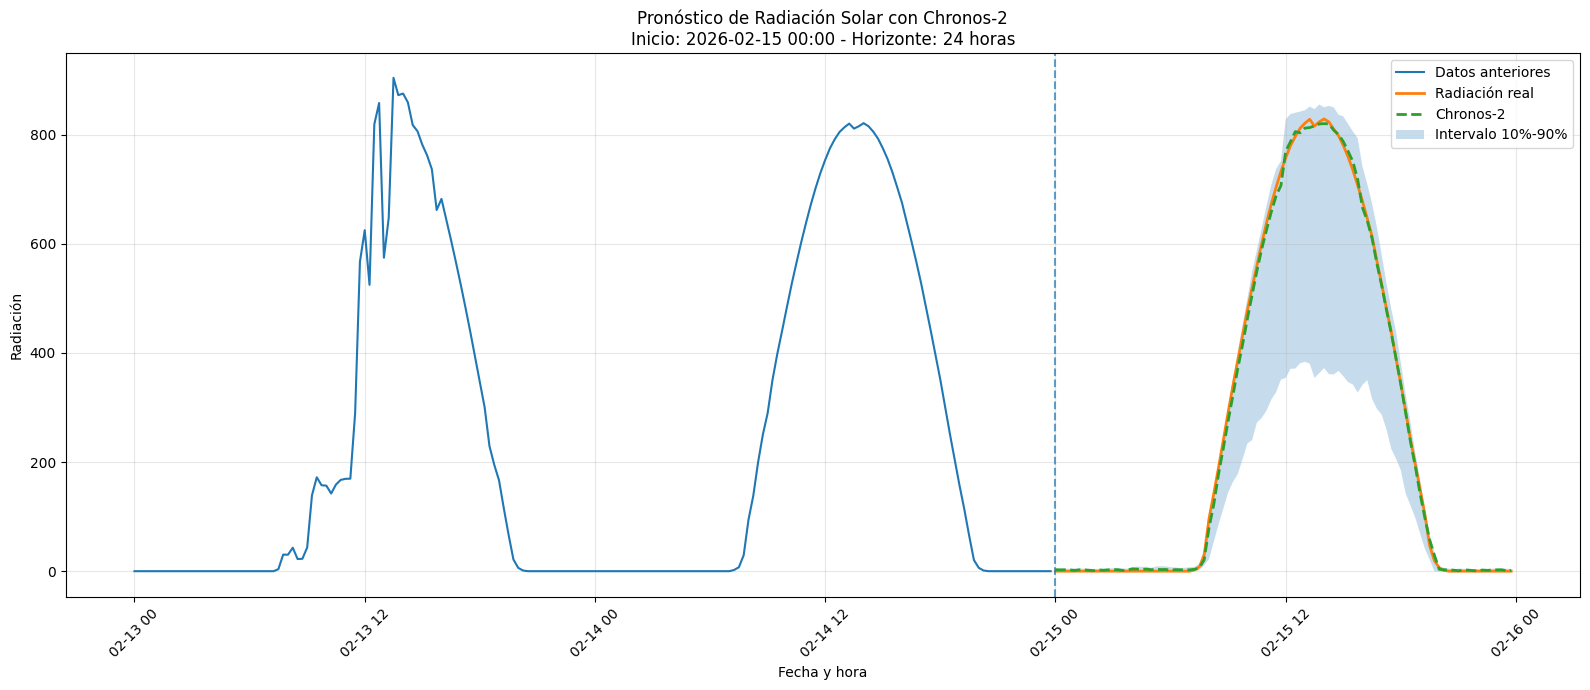

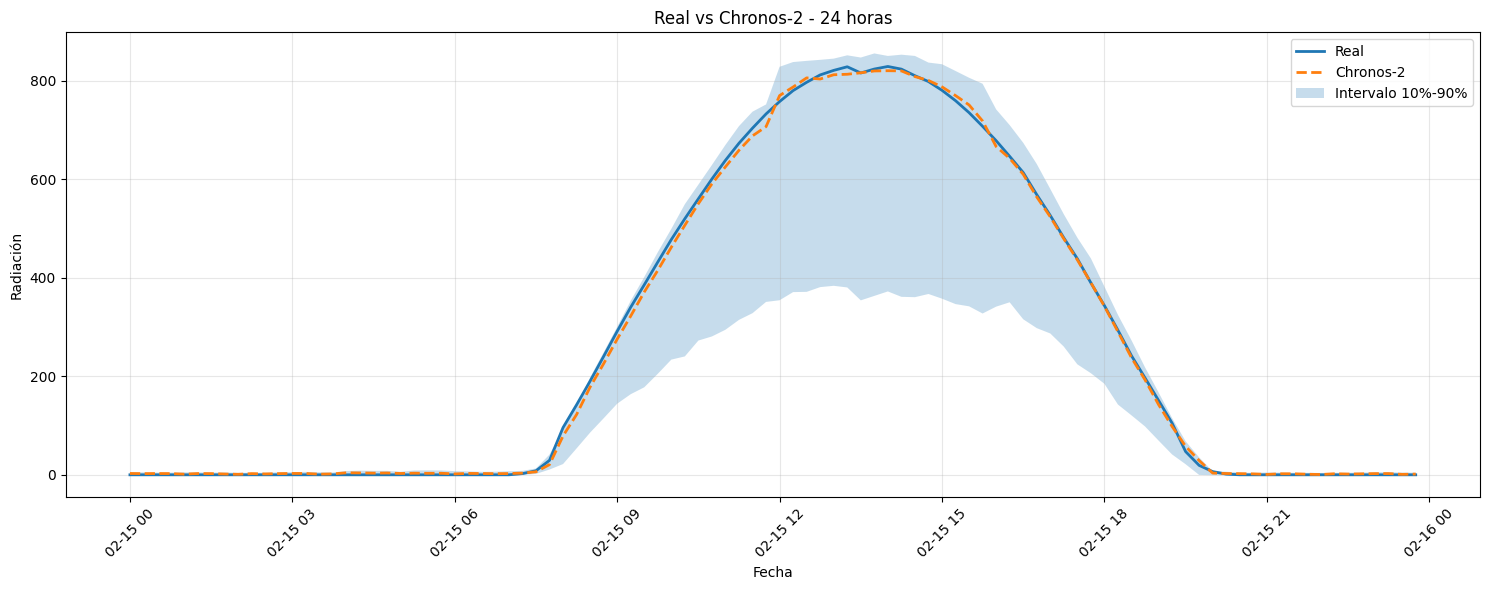



ARCHIVOS GENERADOS
chronos_resultado_periodo.csv
chronos_metricas_periodo.csv
chronos_radiacion_periodo.png
chronos_real_vs_prediccion.png

Proceso terminado.


In [5]:
# ============================================================
# CHRONOS-2 - PRONÓSTICO DE RADIACIÓN SOLAR
# Permite seleccionar:
#   1. Fecha de inicio del período de evaluación
#   2. Cantidad de horas a pronosticar
#
# Datos cada 15 minutos
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.metrics import mean_absolute_error, mean_squared_error
from chronos import Chronos2Pipeline


# ============================================================
# 1. CONFIGURACIÓN
# ============================================================
# MODIFICAR SOLAMENTE ESTAS DOS VARIABLES
# ============================================================

FECHA_INICIO_TEST = "2026-02-15 00:00"

# Ejemplos:
# 6  = 6 horas
# 12 = 12 horas
# 24 = 24 horas
# 48 = 48 horas

HORAS_PREDICCION = 24


# ------------------------------------------------------------
# Como la frecuencia es de 15 minutos:
#
# 1 hora = 4 observaciones
#
# 6 horas  = 24 pasos
# 12 horas = 48 pasos
# 24 horas = 96 pasos
# ------------------------------------------------------------

HORIZONTE = HORAS_PREDICCION * 4


print("=" * 60)
print("CONFIGURACIÓN DEL EXPERIMENTO")
print("=" * 60)

print("Fecha inicio test :", FECHA_INICIO_TEST)
print("Horas predicción  :", HORAS_PREDICCION)
print("Pasos             :", HORIZONTE)


# ============================================================
# 2. CARGAR BASE
# ============================================================

archivo = "unificada.csv"

df = pd.read_csv(
    archivo,
    sep=";",
    low_memory=False
)


print("\nDimensión original:")
print(df.shape)

print("\nColumnas disponibles:")
print(df.columns.tolist())


# ============================================================
# 3. PREPARAR FECHA
# ============================================================

df["fecha"] = pd.to_datetime(
    df["fecha"],
    dayfirst=True,
    errors="coerce"
)


# ============================================================
# 4. CONVERTIR RADIACIÓN A NUMÉRICO
# ============================================================

df["radiacion"] = pd.to_numeric(
    df["radiacion"],
    errors="coerce"
)


# ============================================================
# 5. ELIMINAR FECHAS INVÁLIDAS
# ============================================================

df = df.dropna(
    subset=["fecha"]
)


# ============================================================
# 6. ORDENAR CRONOLÓGICAMENTE
# ============================================================

df = df.sort_values(
    "fecha"
)


# ============================================================
# 7. DEJAR FECHA COMO ÍNDICE
# ============================================================

df = df.set_index(
    "fecha"
)


print("\nRango temporal disponible:")

print(
    df.index.min(),
    "->",
    df.index.max()
)


# ============================================================
# 8. CREAR SERIE DE RADIACIÓN
# ============================================================

radiacion = df[
    "radiacion"
].copy()


# ============================================================
# 9. RESOLVER TIMESTAMPS DUPLICADOS
# ============================================================

if radiacion.index.duplicated().any():

    print("\nSe encontraron timestamps duplicados.")

    radiacion = (
        radiacion
        .groupby(level=0)
        .mean()
    )


# ============================================================
# 10. FRECUENCIA DE 15 MINUTOS
# ============================================================

radiacion = (
    radiacion
    .sort_index()
    .asfreq("15min")
)


# ============================================================
# 11. TRATAMIENTO DE FALTANTES
# ============================================================

print("\nFaltantes antes de interpolar:")

print(
    radiacion.isna().sum()
)


radiacion = radiacion.interpolate(
    method="time",
    limit_direction="both"
)


print("\nFaltantes después de interpolar:")

print(
    radiacion.isna().sum()
)


print("\nCantidad de observaciones:")

print(
    len(radiacion)
)


# ============================================================
# 12. CARGAR CHRONOS-2
# ============================================================

print("\nCargando Chronos-2...")


pipeline = Chronos2Pipeline.from_pretrained(

    "amazon/chronos-2",

    device_map="auto"

)


print("Chronos-2 cargado correctamente.")


# ============================================================
# 13. FUNCIÓN PARA SELECCIONAR EL PERÍODO
# ============================================================

def ejecutar_chronos(
    serie,
    nombre,
    fecha_inicio,
    horizonte
):

    serie = (
        serie
        .dropna()
        .sort_index()
        .copy()
    )


    fecha_inicio = pd.Timestamp(
        fecha_inicio
    )


    # ========================================================
    # COMPROBAR FECHA
    # ========================================================

    if fecha_inicio < serie.index.min():

        raise ValueError(
            "La fecha seleccionada es anterior "
            "al comienzo de la serie."
        )


    if fecha_inicio > serie.index.max():

        raise ValueError(
            "La fecha seleccionada es posterior "
            "al final de la serie."
        )


    # ========================================================
    # TRAIN
    #
    # Solamente datos ANTERIORES al período que
    # queremos pronosticar.
    # ========================================================

    train = serie.loc[
        serie.index < fecha_inicio
    ].copy()


    # ========================================================
    # TEST
    #
    # Datos reales desde la fecha seleccionada.
    # ========================================================

    test = serie.loc[
        serie.index >= fecha_inicio
    ].iloc[
        :horizonte
    ].copy()


    # ========================================================
    # COMPROBAR TEST
    # ========================================================

    if len(test) < horizonte:

        raise ValueError(

            f"No hay suficientes observaciones.\n"
            f"Se necesitan {horizonte} registros.\n"
            f"Solamente existen {len(test)}."
        )


    if len(train) == 0:

        raise ValueError(
            "No existen datos anteriores para entrenamiento."
        )


    # ========================================================
    # CREAR DATAFRAME PARA CHRONOS
    # ========================================================

    context_df = pd.DataFrame({

        "id":
            [nombre] * len(train),

        "timestamp":
            train.index,

        "target":
            train.values

    })


    # ========================================================
    # INFORMACIÓN DEL EXPERIMENTO
    # ========================================================

    print("\n")
    print("=" * 60)
    print("PERÍODO DE EVALUACIÓN")
    print("=" * 60)

    print(
        "Serie:",
        nombre
    )

    print(
        "\nTRAIN:"
    )

    print(
        train.index.min(),
        "->",
        train.index.max()
    )

    print(
        "\nTEST:"
    )

    print(
        test.index.min(),
        "->",
        test.index.max()
    )

    print(
        "\nObservaciones train:",
        len(train)
    )

    print(
        "Observaciones test:",
        len(test)
    )

    print(
        "Horizonte:",
        horizonte,
        "pasos"
    )

    print(
        "Horas pronosticadas:",
        horizonte / 4
    )

    print("=" * 60)


    # ========================================================
    # PRONÓSTICO
    # ========================================================

    pred = pipeline.predict_df(

        context_df,

        prediction_length=horizonte,

        quantile_levels=[
            0.1,
            0.5,
            0.9
        ],

        id_column="id",

        timestamp_column="timestamp",

        target="target",

        freq="15min"

    )


    return train, test, pred


# ============================================================
# 14. EJECUTAR CHRONOS
# ============================================================

train_rad, test_rad, pred_rad = ejecutar_chronos(

    radiacion,

    nombre="radiacion",

    fecha_inicio=FECHA_INICIO_TEST,

    horizonte=HORIZONTE

)


# ============================================================
# 15. OBTENER PRONÓSTICO CENTRAL
# ============================================================

y_real = test_rad.values

y_pred = pred_rad[
    "0.5"
].values


# ============================================================
# 16. CALCULAR MÉTRICAS
# ============================================================

MAE = mean_absolute_error(
    y_real,
    y_pred
)


RMSE = np.sqrt(

    mean_squared_error(
        y_real,
        y_pred
    )

)


# ============================================================
# 17. sMAPE
# ============================================================

denominador = (
    np.abs(y_real)
    +
    np.abs(y_pred)
)


mask = denominador != 0


SMAPE = (

    100 *

    np.mean(

        2 *

        np.abs(
            y_pred[mask]
            -
            y_real[mask]
        )

        /

        denominador[mask]

    )

)


# ============================================================
# 18. WAPE
# ============================================================

if np.sum(np.abs(y_real)) != 0:

    WAPE = (

        100 *

        np.sum(
            np.abs(
                y_real
                -
                y_pred
            )
        )

        /

        np.sum(
            np.abs(y_real)
        )

    )

else:

    WAPE = np.nan


# ============================================================
# 19. MOSTRAR MÉTRICAS
# ============================================================

print("\n")
print("=" * 60)
print("RESULTADOS CHRONOS-2")
print("=" * 60)


print(
    "Período:"
)

print(
    test_rad.index.min(),
    "->",
    test_rad.index.max()
)


print(
    f"\nHorizonte: {HORAS_PREDICCION} horas"
)


print(
    f"MAE   : {MAE:.4f}"
)

print(
    f"RMSE  : {RMSE:.4f}"
)

print(
    f"sMAPE : {SMAPE:.2f}%"
)

print(
    f"WAPE  : {WAPE:.2f}%"
)


# ============================================================
# 20. CREAR TABLA DE RESULTADOS
# ============================================================

resultado = pd.DataFrame({

    "fecha":
        test_rad.index,

    "radiacion_real":
        y_real,

    "chronos":
        y_pred,

    "limite_10":
        pred_rad["0.1"].values,

    "limite_90":
        pred_rad["0.9"].values

})


resultado["error"] = (

    resultado["radiacion_real"]
    -
    resultado["chronos"]

)


resultado["error_absoluto"] = (

    np.abs(
        resultado["error"]
    )

)


print("\nPrimeras predicciones:")

print(
    resultado.head(10)
)


# ============================================================
# 21. GRÁFICO
# ============================================================

plt.figure(
    figsize=(16, 7)
)


# ------------------------------------------------------------
# Mostrar últimas 48 horas anteriores al test
#
# 48 horas x 4 = 192 observaciones
# ------------------------------------------------------------

train_plot = train_rad.iloc[
    -192:
]


plt.plot(

    train_plot.index,

    train_plot.values,

    label="Datos anteriores"

)


# ------------------------------------------------------------
# Datos reales
# ------------------------------------------------------------

plt.plot(

    test_rad.index,

    test_rad.values,

    label="Radiación real",

    linewidth=2

)


# ------------------------------------------------------------
# Pronóstico
# ------------------------------------------------------------

plt.plot(

    pred_rad["timestamp"],

    pred_rad["0.5"],

    label="Chronos-2",

    linewidth=2,

    linestyle="--"

)


# ------------------------------------------------------------
# Intervalo de predicción
# ------------------------------------------------------------

plt.fill_between(

    pred_rad["timestamp"],

    pred_rad["0.1"],

    pred_rad["0.9"],

    alpha=0.25,

    label="Intervalo 10%-90%"

)


# ------------------------------------------------------------
# Línea que marca el inicio del pronóstico
# ------------------------------------------------------------

plt.axvline(

    pd.Timestamp(FECHA_INICIO_TEST),

    linestyle="--",

    alpha=0.7

)


plt.title(

    f"Pronóstico de Radiación Solar con Chronos-2\n"
    f"Inicio: {FECHA_INICIO_TEST} - "
    f"Horizonte: {HORAS_PREDICCION} horas"

)


plt.xlabel(
    "Fecha y hora"
)


plt.ylabel(
    "Radiación"
)


plt.legend()


plt.grid(
    alpha=0.3
)


plt.xticks(
    rotation=45
)


plt.tight_layout()


plt.savefig(

    "chronos_radiacion_periodo.png",

    dpi=300,

    bbox_inches="tight"

)


plt.show()


# ============================================================
# 22. GRÁFICO SOLO REAL VS PREDICCIÓN
# ============================================================

plt.figure(
    figsize=(15, 6)
)


plt.plot(

    resultado["fecha"],

    resultado["radiacion_real"],

    label="Real",

    linewidth=2

)


plt.plot(

    resultado["fecha"],

    resultado["chronos"],

    label="Chronos-2",

    linewidth=2,

    linestyle="--"

)


plt.fill_between(

    resultado["fecha"],

    resultado["limite_10"],

    resultado["limite_90"],

    alpha=0.25,

    label="Intervalo 10%-90%"

)


plt.title(

    f"Real vs Chronos-2 - "
    f"{HORAS_PREDICCION} horas"

)


plt.xlabel(
    "Fecha"
)


plt.ylabel(
    "Radiación"
)


plt.legend()


plt.grid(
    alpha=0.3
)


plt.xticks(
    rotation=45
)


plt.tight_layout()


plt.savefig(

    "chronos_real_vs_prediccion.png",

    dpi=300,

    bbox_inches="tight"

)


plt.show()


# ============================================================
# 23. GUARDAR PRONÓSTICOS
# ============================================================

resultado.to_csv(

    "chronos_resultado_periodo.csv",

    index=False

)


# ============================================================
# 24. GUARDAR MÉTRICAS
# ============================================================

metricas = pd.DataFrame({

    "fecha_inicio": [
        test_rad.index.min()
    ],

    "fecha_fin": [
        test_rad.index.max()
    ],

    "horas_prediccion": [
        HORAS_PREDICCION
    ],

    "horizonte_pasos": [
        HORIZONTE
    ],

    "MAE": [
        MAE
    ],

    "RMSE": [
        RMSE
    ],

    "sMAPE": [
        SMAPE
    ],

    "WAPE": [
        WAPE
    ]

})


metricas.to_csv(

    "chronos_metricas_periodo.csv",

    index=False

)


# ============================================================
# 25. FINAL
# ============================================================

print("\n")
print("=" * 60)
print("ARCHIVOS GENERADOS")
print("=" * 60)

print(
    "chronos_resultado_periodo.csv"
)

print(
    "chronos_metricas_periodo.csv"
)

print(
    "chronos_radiacion_periodo.png"
)

print(
    "chronos_real_vs_prediccion.png"
)

print("\nProceso terminado.")

Guardando resultados en:
resultados_chronos_2026-02-15_00-00_24h


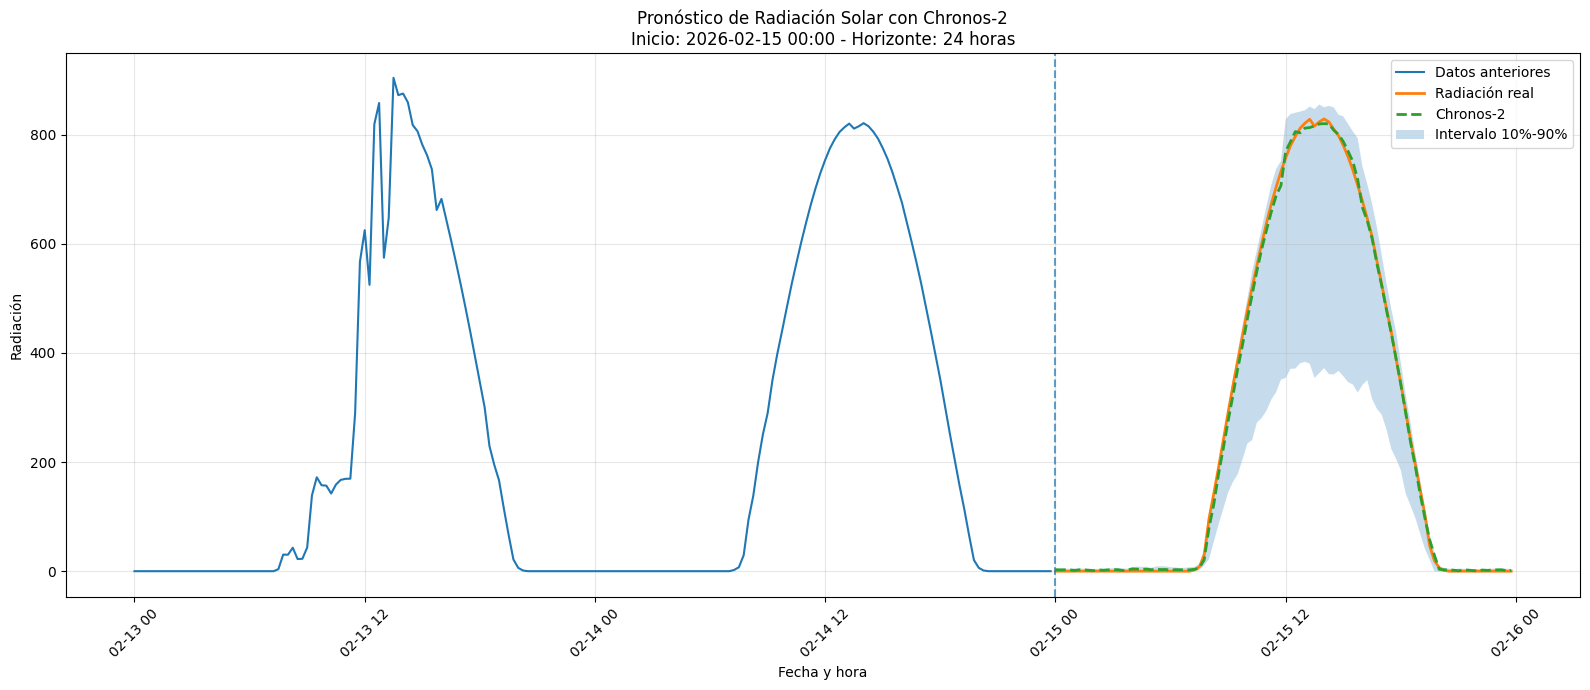

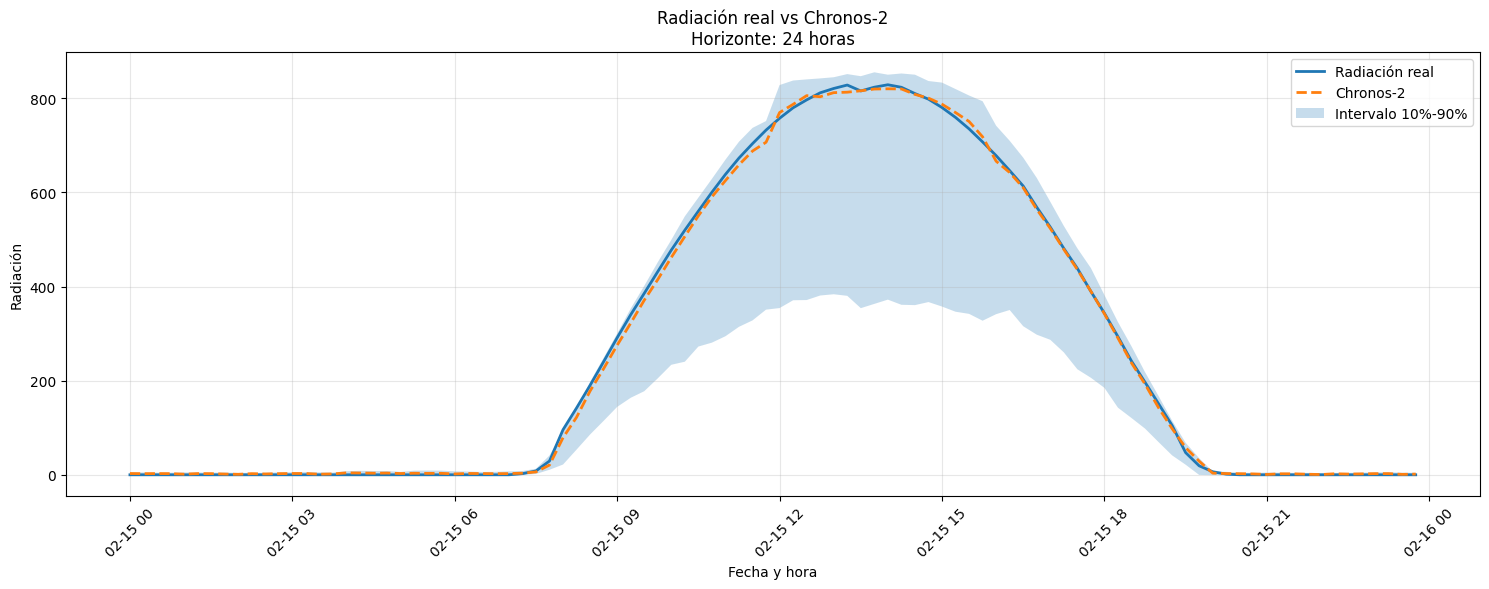

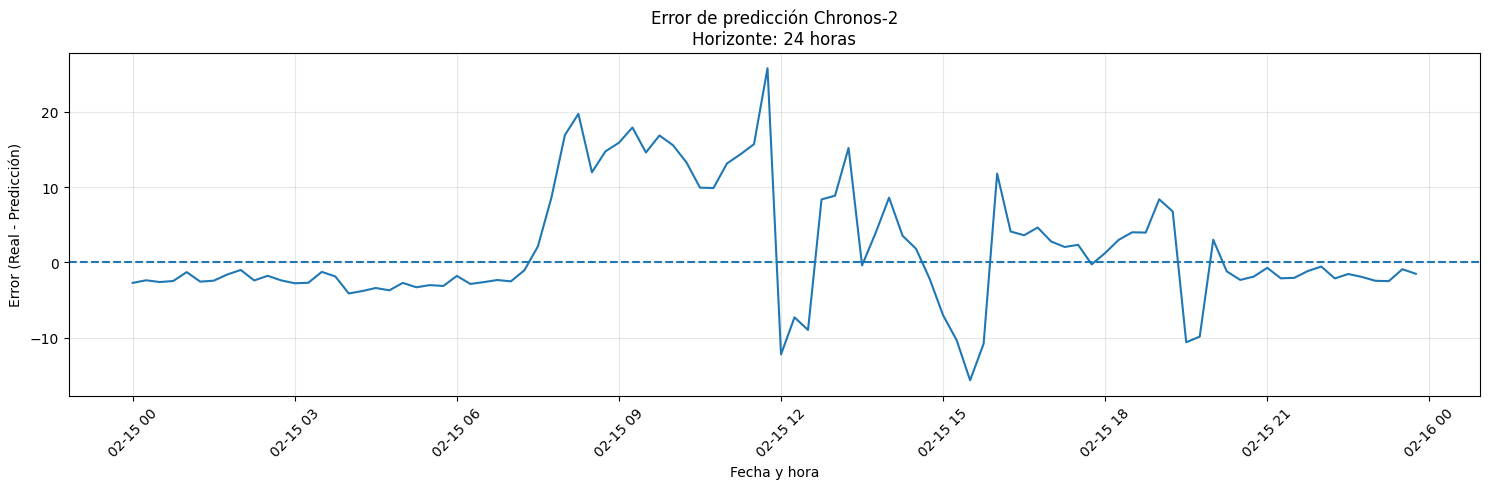



RESULTADOS GUARDADOS CORRECTAMENTE

Carpeta:
resultados_chronos_2026-02-15_00-00_24h

Archivos:
1. pronosticos.csv
2. metricas.csv
3. resumen_experimento.txt
4. 01_pronostico_completo.png
5. 02_real_vs_prediccion.png
6. 03_error_prediccion.png

Experimento finalizado.


In [6]:
# ============================================================
# GUARDAR TODOS LOS RESULTADOS DEL EXPERIMENTO
# ============================================================

import os
import pandas as pd
import matplotlib.pyplot as plt


# ------------------------------------------------------------
# 1. CREAR NOMBRE DE CARPETA
# ------------------------------------------------------------

fecha_nombre = pd.Timestamp(
    FECHA_INICIO_TEST
).strftime("%Y-%m-%d_%H-%M")

nombre_carpeta = (
    f"resultados_chronos_"
    f"{fecha_nombre}_"
    f"{HORAS_PREDICCION}h"
)

os.makedirs(
    nombre_carpeta,
    exist_ok=True
)

print("Guardando resultados en:")
print(nombre_carpeta)


# ------------------------------------------------------------
# 2. GUARDAR PRONÓSTICOS
# ------------------------------------------------------------

ruta_resultados = os.path.join(
    nombre_carpeta,
    "pronosticos.csv"
)

resultado.to_csv(
    ruta_resultados,
    index=False
)


# ------------------------------------------------------------
# 3. GUARDAR MÉTRICAS
# ------------------------------------------------------------

ruta_metricas = os.path.join(
    nombre_carpeta,
    "metricas.csv"
)

metricas.to_csv(
    ruta_metricas,
    index=False
)


# ------------------------------------------------------------
# 4. GRÁFICO COMPLETO
# Datos anteriores + real + predicción
# ------------------------------------------------------------

plt.figure(
    figsize=(16, 7)
)

# Últimas 48 horas antes del pronóstico
train_plot = train_rad.iloc[-192:]


plt.plot(
    train_plot.index,
    train_plot.values,
    label="Datos anteriores"
)


plt.plot(
    test_rad.index,
    test_rad.values,
    label="Radiación real",
    linewidth=2
)


plt.plot(
    pred_rad["timestamp"],
    pred_rad["0.5"],
    label="Chronos-2",
    linewidth=2,
    linestyle="--"
)


plt.fill_between(
    pred_rad["timestamp"],
    pred_rad["0.1"],
    pred_rad["0.9"],
    alpha=0.25,
    label="Intervalo 10%-90%"
)


plt.axvline(
    pd.Timestamp(FECHA_INICIO_TEST),
    linestyle="--",
    alpha=0.7
)


plt.title(
    f"Pronóstico de Radiación Solar con Chronos-2\n"
    f"Inicio: {FECHA_INICIO_TEST} - "
    f"Horizonte: {HORAS_PREDICCION} horas"
)

plt.xlabel("Fecha y hora")

plt.ylabel("Radiación")

plt.legend()

plt.grid(alpha=0.3)

plt.xticks(rotation=45)

plt.tight_layout()


ruta_grafico1 = os.path.join(
    nombre_carpeta,
    "01_pronostico_completo.png"
)

plt.savefig(
    ruta_grafico1,
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ------------------------------------------------------------
# 5. GRÁFICO REAL VS PREDICCIÓN
# ------------------------------------------------------------

plt.figure(
    figsize=(15, 6)
)


plt.plot(
    resultado["fecha"],
    resultado["radiacion_real"],
    label="Radiación real",
    linewidth=2
)


plt.plot(
    resultado["fecha"],
    resultado["chronos"],
    label="Chronos-2",
    linewidth=2,
    linestyle="--"
)


plt.fill_between(
    resultado["fecha"],
    resultado["limite_10"],
    resultado["limite_90"],
    alpha=0.25,
    label="Intervalo 10%-90%"
)


plt.title(
    f"Radiación real vs Chronos-2\n"
    f"Horizonte: {HORAS_PREDICCION} horas"
)

plt.xlabel("Fecha y hora")

plt.ylabel("Radiación")

plt.legend()

plt.grid(alpha=0.3)

plt.xticks(rotation=45)

plt.tight_layout()


ruta_grafico2 = os.path.join(
    nombre_carpeta,
    "02_real_vs_prediccion.png"
)

plt.savefig(
    ruta_grafico2,
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ------------------------------------------------------------
# 6. GRÁFICO DEL ERROR
# ------------------------------------------------------------

plt.figure(
    figsize=(15, 5)
)


plt.plot(
    resultado["fecha"],
    resultado["error"],
    linewidth=1.5
)


plt.axhline(
    y=0,
    linestyle="--"
)


plt.title(
    f"Error de predicción Chronos-2\n"
    f"Horizonte: {HORAS_PREDICCION} horas"
)

plt.xlabel("Fecha y hora")

plt.ylabel(
    "Error (Real - Predicción)"
)

plt.grid(alpha=0.3)

plt.xticks(rotation=45)

plt.tight_layout()


ruta_grafico3 = os.path.join(
    nombre_carpeta,
    "03_error_prediccion.png"
)

plt.savefig(
    ruta_grafico3,
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ------------------------------------------------------------
# 7. CREAR ARCHIVO TXT CON RESUMEN
# ------------------------------------------------------------

ruta_resumen = os.path.join(
    nombre_carpeta,
    "resumen_experimento.txt"
)


with open(
    ruta_resumen,
    "w",
    encoding="utf-8"
) as f:

    f.write(
        "RESULTADOS CHRONOS-2\n"
    )

    f.write(
        "=" * 50 + "\n\n"
    )

    f.write(
        "Variable: Radiación solar\n"
    )

    f.write(
        f"Fecha inicio: "
        f"{test_rad.index.min()}\n"
    )

    f.write(
        f"Fecha fin: "
        f"{test_rad.index.max()}\n"
    )

    f.write(
        f"Horizonte: "
        f"{HORAS_PREDICCION} horas\n"
    )

    f.write(
        f"Pasos: "
        f"{HORIZONTE}\n"
    )

    f.write(
        f"Frecuencia: 15 minutos\n\n"
    )

    f.write(
        "MÉTRICAS\n"
    )

    f.write(
        "-" * 30 + "\n"
    )

    f.write(
        f"MAE: {MAE:.4f}\n"
    )

    f.write(
        f"RMSE: {RMSE:.4f}\n"
    )

    f.write(
        f"sMAPE: {SMAPE:.2f}%\n"
    )

    f.write(
        f"WAPE: {WAPE:.2f}%\n"
    )


# ------------------------------------------------------------
# 8. MOSTRAR ARCHIVOS GENERADOS
# ------------------------------------------------------------

print("\n")
print("=" * 60)
print("RESULTADOS GUARDADOS CORRECTAMENTE")
print("=" * 60)

print("\nCarpeta:")
print(nombre_carpeta)

print("\nArchivos:")

print("1. pronosticos.csv")
print("2. metricas.csv")
print("3. resumen_experimento.txt")
print("4. 01_pronostico_completo.png")
print("5. 02_real_vs_prediccion.png")
print("6. 03_error_prediccion.png")

print("\nExperimento finalizado.")